# 1A pilot v2.1 — 5 tasks × 15 models (1.5–8B) × 7 noise conditions

> **Tóm tắt (VI):** Bản v2.1 của pilot 1A. So với v2: (1) sửa lỗi tách token nhãn (Phi-3.5); (2) thêm độ dài câu vào hồi quy; (3) thêm 8 mô hình nhỏ để có **nhiều cỡ trong cùng một họ** (cùng tokenizer); (4) thêm 4 bộ dữ liệu: cảm xúc (VSMEC), ngôn từ thù ghét trên mạng xã hội (ViHSD, có sẵn nhiễu thật), suy luận (XNLI), đọc hiểu trắc nghiệm (ViMMRC). Kết quả VSFC của v2 được dùng lại để tiết kiệm CU.

**Changes from v2** (v2 results: `MyDrive/llm-research/1A-pilot-v2/`)

| v2 issue | v2.1 change |
|---|---|
| Phi-3.5 `label_mass` = 0%: " tiêu cực" tokenized alone is `['▁', '▁ti', …]` (an extra space token), in context it is `['▁ti', …]` | **Labels tokenized in context**: tokens of (prompt + label) minus tokens of the prompt |
| "Broken syllables" had a negative coefficient: likely sentence length (long sentences have more broken syllables *and* more clues) | **log(length) added** as a covariate in every item-level regression |
| One size per family | **15 models, 5 families with 2–3 sizes each.** Within a family the tokenizer is fixed, so a size effect cannot be a tokenizer effect |
| One task | **5 tasks** (below) |

| Task | What | Classes | Items | Noise on |
|---|---|---|---|---|
| `vsfc` | student feedback sentiment | 3 | 300 | sentence |
| `vsmec` | social media emotion | 7 | 245 | sentence |
| `vihsd` | social media hate speech — **already partly unaccented in the original** | 3 | 300 | comment |
| `xnli` | natural language inference (translated) | 3 | 300 | premise + hypothesis |
| `vimmrc` | multiple-choice reading comprehension | 4 | 160 | article + question + options |

**Runtime:** L4 GPU. Roughly **5–7 hours (15–20 CU)** for everything. Models run from small to large, and every finished (model, task) is saved, so you can stop and continue in later sessions: just Run all again. To run a subset, edit `MODELS` / `TASKS` in section 1.

⚠️ Colab disconnects after ~90 min without interaction: keep the tab open. When you are done: `Runtime → Disconnect and delete runtime`.

## 0. Setup

In [1]:
import sys, os
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install -U transformers accelerate

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/llm-research"
else:
    ROOT = "outputs"
OUT_DIR = f"{ROOT}/1A-pilot-v2.1"
V2_DIR = f"{ROOT}/1A-pilot-v2"  # VSFC results from v2 are reused when they are still valid
os.makedirs(f"{OUT_DIR}/preds", exist_ok=True)
print("Saving results to", OUT_DIR)

Mounted at /content/drive
Saving results to /content/drive/MyDrive/llm-research/1A-pilot-v2.1


In [3]:
# Only needed for gated models. In Colab: 🔑 Secrets panel → add HF_TOKEN,
# and accept each model's licence on its Hugging Face page first.
HF_TOKEN = None
if IN_COLAB:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        print("No HF_TOKEN secret — gated models will be skipped.")

No HF_TOKEN secret — gated models will be skipped.


In [4]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(p.name, f"{p.total_memory / 1e9:.1f} GB")
    # T4 (compute capability 7.5) has no real bfloat16, so it gets float16
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    print("⚠️ No GPU. Runtime → Change runtime type → L4 GPU")
    DTYPE = torch.float32
print("dtype:", DTYPE)

NVIDIA L4 23.7 GB
dtype: torch.bfloat16


## 1. Config

Models are listed **small to large**, so the cheap ones finish first. `MODEL_INFO` gives each model's family and size; a family shares one tokenizer, which is what makes the size comparison clean.

In [5]:
MODEL_INFO = {  # name: (family, size in billions)
    "Qwen/Qwen2.5-1.5B-Instruct": ("Qwen2.5", 1.5),
    "Qwen/Qwen3-1.7B": ("Qwen3", 1.7),
    "SeaLLMs/SeaLLMs-v3-1.5B-Chat": ("SeaLLMs-v3", 1.5),
    "bigscience/bloomz-1b7": ("bloomz", 1.7),
    "vilm/vinallama-2.7b-chat": ("VinaLLaMA", 2.7),
    "Qwen/Qwen2.5-3B-Instruct": ("Qwen2.5", 3.1),   # research-only licence: fine for a paper
    "bigscience/bloomz-3b": ("bloomz", 3.0),
    "Qwen/Qwen3-4B": ("Qwen3", 4.0),
    "microsoft/Phi-3.5-mini-instruct": ("Phi-3.5", 3.8),
    "Qwen/Qwen2.5-7B-Instruct": ("Qwen2.5", 7.6),
    "Qwen/Qwen3-8B": ("Qwen3", 8.2),
    "SeaLLMs/SeaLLMs-v3-7B-Chat": ("SeaLLMs-v3", 7.6),
    "vilm/vinallama-7b-chat": ("VinaLLaMA", 6.9),
    "bigscience/bloomz-7b1": ("bloomz", 7.1),
    "mistralai/Mistral-7B-Instruct-v0.3": ("Mistral", 7.2),
}
GATED_INFO = {
    "meta-llama/Llama-3.2-3B-Instruct": ("Llama-3", 3.2),
    "meta-llama/Llama-3.1-8B-Instruct": ("Llama-3", 8.0),
    "Viet-Mistral/Vistral-7B-Chat": ("Mistral", 7.3),   # Mistral + Vietnamese
    "CohereLabs/aya-expanse-8b": ("Aya", 8.0),
}
if HF_TOKEN:
    MODEL_INFO.update(GATED_INFO)
MODELS = list(MODEL_INFO)

TASKS = ["vsfc", "vsmec", "vihsd", "xnli", "vimmrc"]
CONDITIONS = ["clean", "partial25", "partial50", "partial75", "strip", "teencode", "mixed"]
SEED = 42
TOKEN_BUDGET = 4096          # max padded tokens per forward batch; halved automatically on out-of-memory
MIN_ABOVE_CHANCE = 0.12      # gate: clean accuracy must beat chance by this much to enter the analysis
DELETE_WEIGHTS_AFTER_USE = IN_COLAB   # 7B weights are ~15 GB each; keeps Colab's disk from filling up
REUSE_V2 = True              # reuse v2 VSFC predictions when the items match and the model was not affected
V2_REDO = {"microsoft/Phi-3.5-mini-instruct"}   # hit by the label tokenization bug in v2

## 2. Noise generator

Same as v2 (same rules, same random seeds), so the VSFC items are identical and v2 results can be reused.
For tasks with several text fields (XNLI, ViMMRC), every field gets the noise.

In [6]:
import random, re, unicodedata

def strip_diacritics(s):
    s = s.replace("đ", "d").replace("Đ", "D")
    s = unicodedata.normalize("NFD", s)
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", s)

def partial_strip(text, rate, rng):
    words = text.split(" ")
    candidates = [i for i, w in enumerate(words) if strip_diacritics(w) != w]
    chosen = set(rng.sample(candidates, round(rate * len(candidates))))
    return " ".join(strip_diacritics(w) if i in chosen else w for i, w in enumerate(words))

TEENCODE = {
    "giáo viên": "gv", "giảng viên": "gv", "sinh viên": "sv", "bài tập": "bt", "học sinh": "hs",
    "không": "ko", "được": "dc", "gì": "j", "với": "vs", "mình": "mk", "rồi": "r",
    "vậy": "v", "bạn": "bn", "quá": "wa", "nhiều": "nhìu", "người": "ng", "trước": "trc",
    "cũng": "cx", "thôi": "thui", "biết": "bít", "yêu": "iu", "giờ": "h",
    "nhưng": "nhg", "lắm": "lém", "thích": "thik", "những": "nhữg", "hiểu": "hỉu",
}
_teen_re = re.compile(
    r"(?<!\w)(" + "|".join(sorted(map(re.escape, TEENCODE), key=len, reverse=True)) + r")(?!\w)",
    re.IGNORECASE,
)

def teencode(text):
    return _teen_re.sub(lambda m: TEENCODE[m.group(0).lower()], text)

def make_noisy(text, cond, item_id, field_idx=0):
    # field 0 keeps v2's seed, so single-field tasks reproduce v2 exactly
    rng = random.Random(f"{SEED}-{item_id}-{cond}" + (f"-{field_idx}" if field_idx else ""))
    if cond == "clean":
        return text
    if cond == "strip":
        return strip_diacritics(text)
    if cond.startswith("partial"):
        return partial_strip(text, int(cond[len("partial"):]) / 100, rng)
    if cond == "teencode":
        return teencode(text)
    if cond == "mixed":
        return partial_strip(teencode(text), 0.5, rng)
    raise ValueError(cond)

def accent_share(text):
    # share of alphabetic syllables that carry a diacritic (edited Vietnamese: ~0.85)
    words = [w for w in text.split() if w.isalpha()]
    return sum(strip_diacritics(w) != w for w in words) / max(len(words), 1)

assert strip_diacritics("Tôi muốn đặt vé máy bay") == "Toi muon dat ve may bay"
assert teencode("giáo viên không nói gì") == "gv ko nói j"

## 3. Tasks

Each task defines: where the data comes from, which fields get noise, the label words, the instruction, and the answer prefill. Labels are sampled **balanced** per class, so chance = 1 / number of classes.

✏️ The Vietnamese label words and instructions are worth a second look from you, especially ViHSD's definitions.

In [7]:
import ast
import pandas as pd

PARQUET = "https://huggingface.co/datasets/{}/resolve/refs%2Fconvert%2Fparquet/{}/test/0000.parquet"

TASK_SPECS = {
    "vsfc": dict(
        source=("uitnlp/vietnamese_students_feedback", "default"), fields=["sentence"], label_col="sentiment",
        classes=[0, 1, 2], labels=["tiêu cực", "trung tính", "tích cực"], per_class=100,
        instruction=("Phân loại cảm xúc của câu nhận xét sau của sinh viên. "
                     "Trả lời bằng đúng một nhãn: tiêu cực, trung tính, hoặc tích cực.\n\nCâu: {sentence}"),
        prefill="Nhãn:", nll_context="Nhận xét của sinh viên:"),
    "vsmec": dict(
        source=("ura-hcmut/UIT-VSMEC", "default"), fields=["Sentence"], label_col="Emotion",
        classes=["Enjoyment", "Sadness", "Anger", "Fear", "Disgust", "Surprise", "Other"],
        labels=["vui vẻ", "buồn bã", "tức giận", "sợ hãi", "ghê tởm", "ngạc nhiên", "khác"], per_class=35,
        instruction=("Câu bình luận sau thể hiện cảm xúc gì? Trả lời bằng đúng một nhãn: "
                     "vui vẻ, buồn bã, tức giận, sợ hãi, ghê tởm, ngạc nhiên, hoặc khác.\n\nCâu: {Sentence}"),
        prefill="Nhãn:", nll_context="Bình luận trên mạng xã hội:"),
    "vihsd": dict(
        source=("ura-hcmut/UIT-ViHSD", "default"), fields=["free_text"], label_col="label_id",
        classes=[0, 1, 2], labels=["bình thường", "xúc phạm", "thù ghét"], per_class=100,
        instruction=("Phân loại bình luận mạng xã hội sau. Trả lời bằng đúng một nhãn: "
                     "bình thường (không có lời lẽ xấu), xúc phạm (có lời lẽ thô tục nhưng không nhắm vào ai), "
                     "hoặc thù ghét (công kích, lăng mạ một người hay một nhóm người).\n\nBình luận: {free_text}"),
        prefill="Nhãn:", nll_context="Bình luận trên mạng xã hội:"),
    "xnli": dict(
        source=("facebook/xnli", "vi"), fields=["premise", "hypothesis"], label_col="label",
        classes=[0, 1, 2], labels=["kéo theo", "trung lập", "mâu thuẫn"], per_class=100,
        instruction=("Cho tiền đề và giả thuyết sau. Giả thuyết có được suy ra từ tiền đề không? "
                     "Trả lời bằng đúng một nhãn: kéo theo (giả thuyết chắc chắn đúng), trung lập (không xác định được), "
                     "hoặc mâu thuẫn (giả thuyết chắc chắn sai).\n\nTiền đề: {premise}\nGiả thuyết: {hypothesis}"),
        prefill="Nhãn:", nll_context="Văn bản:"),
    "vimmrc": dict(
        source=("ura-hcmut/ViMMRC", "default"), fields=["article", "question", "options"], label_col="answer",
        classes=["A", "B", "C", "D"], labels=["A", "B", "C", "D"], per_class=40,
        instruction=("Đọc đoạn văn và chọn đáp án đúng cho câu hỏi. Trả lời bằng đúng một chữ cái: A, B, C hoặc D.\n\n"
                     "Đoạn văn: {article}\n\nCâu hỏi: {question}\n{options}"),
        prefill="Đáp án:", nll_context="Bài đọc:"),
}

def load_task(task):
    spec = TASK_SPECS[task]
    raw = pd.read_parquet(PARQUET.format(*spec["source"]))
    if task == "vimmrc":
        raw["options"] = [ "\n".join(f"{l}. {o}" for l, o in zip("ABCD", ast.literal_eval(x))) for x in raw.options]
    raw = raw[raw[spec["label_col"]].isin(spec["classes"])]
    sample = raw.groupby(spec["label_col"]).sample(n=spec["per_class"], random_state=SEED).reset_index(drop=True)
    rows = []
    for item_id, r in enumerate(sample.itertuples(index=False)):
        r = r._asdict()
        label = spec["classes"].index(r[spec["label_col"]])
        for c in CONDITIONS:
            row = {"task": task, "item_id": item_id, "label": label, "cond": c}
            for fi, f in enumerate(spec["fields"]):
                row[f] = make_noisy(r[f], c, item_id, fi)
                row[f"{f}_clean"] = r[f]
            row["text"] = "\n".join(row[f] for f in spec["fields"])
            row["clean"] = "\n".join(row[f"{f}_clean"] for f in spec["fields"])
            rows.append(row)
    return pd.DataFrame(rows)

DATA = {t: load_task(t) for t in TASKS}
pd.concat(DATA.values())[["task", "item_id", "cond", "text", "clean"]].to_csv(f"{OUT_DIR}/noisy_items.csv", index=False)

overview = pd.DataFrame([{
    "task": t, "items": d.item_id.nunique(), "classes": len(TASK_SPECS[t]["labels"]),
    "median_syllables": d[d.cond == "clean"].clean.str.split().str.len().median(),
    "accent_share_original": d[d.cond == "clean"].clean.map(accent_share).mean(),
    "changed_by_teencode": (d[d.cond == "teencode"].text != d[d.cond == "teencode"].clean).mean(),
} for t, d in DATA.items()])
print("accent_share_original: share of syllables with diacritics in the ORIGINAL text (ViHSD is already noisier)")
overview.round(2)

accent_share_original: share of syllables with diacritics in the ORIGINAL text (ViHSD is already noisier)


,task,items,classes,median_syllables,accent_share_original,changed_by_teencode
0,vsfc,300,3,10.0,0.88,0.67
1,vsmec,245,7,11.0,0.84,0.64
2,vihsd,300,3,9.0,0.68,0.44
3,xnli,300,3,36.0,0.86,0.93
4,vimmrc,160,4,300.0,0.86,0.99


In [8]:
for t, d in DATA.items():
    print(f"── {t}")
    for c in CONDITIONS:
        print(f"   {c:10} {d[(d.item_id == 0) & (d.cond == c)].text.iloc[0][:110]!r}")

── vsfc
   clean      'giáo viên giảng dạy khá nhanh .'
   partial25  'giáo viên giảng dạy kha nhanh .'
   partial50  'giáo vien giảng dạy kha nhanh .'
   partial75  'giao viên giang day kha nhanh .'
   strip      'giao vien giang day kha nhanh .'
   teencode   'gv giảng dạy khá nhanh .'
   mixed      'gv giang day khá nhanh .'
── vsmec
   clean      'nuôi kiểu đéo gì lại để nó như thế này ??? thằg chủ có tâm hồn thối rữa à ??'
   partial25  'nuôi kieu đéo gì lại để nó như thế này ??? thằg chủ co tâm hon thối rữa a ??'
   partial50  'nuoi kieu đéo gi lại de nó nhu thế này ??? thằg chu có tâm hon thối rua a ??'
   partial75  'nuoi kieu đéo gi lai de nó nhu the nay ??? thag chu co tam hon thối rua à ??'
   strip      'nuoi kieu deo gi lai de no nhu the nay ??? thag chu co tam hon thoi rua a ??'
   teencode   'nuôi kiểu đéo j lại để nó như thế này ??? thằg chủ có tâm hồn thối rữa à ??'
   mixed      'nuôi kieu deo j lại để nó nhu thế nay ??? thag chu co tâm hồn thối rua à ??'
── vihsd
   

## 4. Tokenizer statistics, per item (CPU)

- **fertility** = tokens ÷ syllables of the *clean* text (same denominator for every condition).
- **broken_rate** = share of syllables split into more than one token.
- **fragment_rate** = share of tokens that are not a whole character on their own.

In [9]:
from transformers import AutoTokenizer
from tqdm.auto import tqdm

def syllable_spans(text):
    return [(m.start(), m.end()) for m in re.finditer(r"\S+", text) if any(ch.isalpha() for ch in m.group())]

def item_tok_stats(tok, text, clean):
    enc = tok(text, add_special_tokens=False, return_offsets_mapping=True)
    ids, offs = enc["input_ids"], enc["offset_mapping"]
    spans = syllable_spans(text)
    j, n_broken = 0, 0
    for a, b in spans:  # offsets are sorted, so walk them once
        while j < len(offs) and offs[j][1] <= a:
            j += 1
        k, n = j, 0
        while k < len(offs) and offs[k][0] < b:
            n += offs[k][1] > offs[k][0]
            k += 1
        n_broken += n > 1
    return {"n_tok": len(ids), "n_syl": len(spans), "clean_syl": len(syllable_spans(clean)),
            "n_broken": n_broken, "n_frag": sum("�" in tok.decode([i]) for i in ids)}

def tok_items_path(name):
    return f"{OUT_DIR}/tokenizer/{name.replace('/', '__')}.csv"

os.makedirs(f"{OUT_DIR}/tokenizer", exist_ok=True)
tok_failed = {}
for name in tqdm(MODELS, desc="tokenizers"):
    if os.path.exists(tok_items_path(name)):
        continue
    try:
        tok = AutoTokenizer.from_pretrained(name, token=HF_TOKEN)
    except Exception as e:
        tok_failed[name] = repr(e)[:200]
        continue
    rows = [{"model": name, "task": r.task, "item_id": r.item_id, "cond": r.cond, **item_tok_stats(tok, r.text, r.clean)}
            for d in DATA.values() for r in d.itertuples()]
    pd.DataFrame(rows).to_csv(tok_items_path(name), index=False)
for name, err in tok_failed.items():
    print("✗ tokenizer failed, model skipped:", name, err)
MODELS = [m for m in MODELS if m not in tok_failed]

tok_items = pd.concat([pd.read_csv(tok_items_path(m)) for m in MODELS])
tok_items = tok_items[tok_items.task.isin(TASKS)]
g = tok_items.groupby(["model", "task", "cond"]).sum(numeric_only=True)
tok_stats = pd.DataFrame({
    "fertility": g.n_tok / g.clean_syl,
    "broken_rate": g.n_broken / g.n_syl,
    "fragment_rate": g.n_frag / g.n_tok,
}).reset_index()
tok_stats.to_csv(f"{OUT_DIR}/tokenizer_stats.csv", index=False)
print("fertility, VSFC (other tasks look alike):")
tok_stats[tok_stats.task == TASKS[0]].pivot(index="model", columns="cond", values="fertility")[CONDITIONS].round(2)

tokenizers:   0%|          | 0/19 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


✗ tokenizer failed, model skipped: meta-llama/Llama-3.1-8B-Instruct OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/meta-llama/Llama-3.1-8B-Instruct.\n401 Client Error. (Request ID: Root=1-6adf72bd-70f73d267cfd
✗ tokenizer failed, model skipped: Viet-Mistral/Vistral-7B-Chat OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/Viet-Mistral/Vistral-7B-Chat.\n401 Client Error. (Request ID: Root=1-6adf72bd-753242ca01c03720
✗ tokenizer failed, model skipped: CohereLabs/aya-expanse-8b OSError('You are trying to access a gated repo.\nMake sure to have access to it at https://huggingface.co/CohereLabs/aya-expanse-8b.\n401 Client Error. (Request ID: Root=1-6adf72be-4951c03a70634d597bc
fertility, VSFC (other tasks look alike):


cond,clean,partial25,partial50,partial75,strip,teencode,mixed
model,,,,,,,
Qwen/Qwen2.5-1.5B-Instruct,1.29,1.37,1.45,1.53,1.60,1.29,1.39
Qwen/Qwen2.5-3B-Instruct,1.29,1.37,1.45,1.53,1.60,1.29,1.39
Qwen/Qwen2.5-7B-Instruct,1.29,1.37,1.45,1.53,1.60,1.29,1.39
Qwen/Qwen3-1.7B,1.29,1.37,1.45,1.53,1.60,1.29,1.39
Qwen/Qwen3-4B,1.29,1.37,1.45,1.53,1.60,1.29,1.39
Qwen/Qwen3-8B,1.29,1.37,1.45,1.53,1.60,1.29,1.39
SeaLLMs/SeaLLMs-v3-1.5B-Chat,1.29,1.37,1.45,1.53,1.60,1.29,1.39
SeaLLMs/SeaLLMs-v3-7B-Chat,1.29,1.37,1.45,1.53,1.60,1.29,1.39
bigscience/bloomz-1b7,1.18,1.24,1.30,1.35,1.41,1.19,1.25


## 5. Model evaluation (GPU)

Same method as v2: label scoring after a prefilled answer ("Nhãn:" or "Đáp án:"), both casings, batch calibration per condition, NLL per clean syllable, and 6 free greedy answers per (model, task) as diagnostics.

**New in v2.1:**
- **Labels are tokenized in context.** The label's tokens are the tokens of (prompt + " " + label) minus the tokens of the prompt. In v2, Phi-3.5's tokenizer added a stray space token to labels tokenized alone, so its label mass was 0%.
- **One forward pass per item when every label is a single token** (ViMMRC's A/B/C/D): the next-token distribution scores all options at once, which makes the long reading-comprehension prompts affordable.
- **Batches by token budget**, sorted by length. On out-of-memory the budget is halved and the task retried.
- **VSFC is reused from v2** for every model except Phi-3.5, if v2's items are identical (checked).

In [10]:
import gc, time, shutil
import torch.nn.functional as F
from transformers import AutoModelForCausalLM
from huggingface_hub import constants as hf_constants

def prompt_text(tok, task, row, prefill=True):
    spec = TASK_SPECS[task]
    msg = spec["instruction"].format(**{f: row[f] for f in spec["fields"]})
    if tok.chat_template:
        # enable_thinking=False only matters for Qwen3; other templates ignore it
        s = tok.apply_chat_template([{"role": "user", "content": msg}], tokenize=False,
                                    add_generation_prompt=True, enable_thinking=False)
        return s + (spec["prefill"] if prefill else ""), False
    return f"{msg}\n{spec['prefill']}" if prefill else msg, True

def label_variants(tok, prompt, add_special, p_ids, labels):
    # per label, the token ids of each casing, tokenized in context (after the prompt)
    out = []
    for l in labels:
        vs = []
        for v in dict.fromkeys([l, l.capitalize()]):
            full = tok(prompt + " " + v, add_special_tokens=add_special)["input_ids"]
            if full[:len(p_ids)] == p_ids and len(full) > len(p_ids):
                vs.append(full[len(p_ids):])
            else:  # the label merged into the prompt's last token; fall back to the label alone
                vs.append(tok(" " + v, add_special_tokens=False)["input_ids"])
        out.append(vs)
    return out

def nll_ids(tok, task, text):
    # score only the text, after a short clean context (Qwen has no BOS token to start from)
    ctx = TASK_SPECS[task]["nll_context"]
    enc = tok(f"{ctx} {text}", add_special_tokens=True, return_offsets_mapping=True)
    first = next(i for i, (a, b) in enumerate(enc["offset_mapping"]) if b > a and a >= len(ctx))
    return enc["input_ids"], first

def pad_batch(seqs, pad_id, device):
    L = max(map(len, seqs))
    ids = torch.full((len(seqs), L), pad_id)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s)
        mask[i, :len(s)] = 1
    return ids.to(device), mask.to(device)

@torch.no_grad()
def score(model, pad_id, seqs, starts):
    # seqs[i][starts[i]:] is the scored part; returns (sum log-prob, n scored tokens) per sequence
    ids, mask = pad_batch(seqs, pad_id, model.device)
    logits = model(input_ids=ids, attention_mask=mask).logits
    pick = torch.zeros_like(mask, dtype=torch.bool)  # pick[i, t]: logits at t predict token t+1
    for i, (s, st) in enumerate(zip(seqs, starts)):
        pick[i, st - 1:len(s) - 1] = True
    sel = logits[pick]
    del logits
    tgt = ids[:, 1:][pick[:, :-1]]
    # log p(target) = logit(target) - logsumexp(logits), in chunks: a full float32 log-softmax over a
    # 150k vocabulary needs ~5 GB for a 8k-token batch
    tok_lp = torch.cat([
        sel[i:i + 1024].gather(1, tgt[i:i + 1024, None]).squeeze(1).float() - sel[i:i + 1024].float().logsumexp(-1)
        for i in range(0, len(sel), 1024)])
    owner = pick.nonzero()[:, 0]
    sums = torch.zeros(len(seqs), device=tok_lp.device).index_add_(0, owner, tok_lp)
    return sums.cpu().tolist(), pick.sum(1).cpu().tolist()

@torch.no_grad()
def next_token_logprobs(model, pad_id, seqs):
    ids, mask = pad_batch(seqs, pad_id, model.device)
    logits = model(input_ids=ids, attention_mask=mask).logits
    last = logits[torch.arange(len(seqs), device=logits.device), mask.sum(1) - 1]
    del logits
    return F.log_softmax(last.float(), dim=-1).cpu()

def token_batches(items, length, budget):
    # longest first, so an out-of-memory error shows up at the start
    order = sorted(range(len(items)), key=lambda i: -length(items[i]))
    batch, longest = [], 0
    for i in order:
        n = length(items[i])
        if batch and max(longest, n) * (len(batch) + 1) > budget:
            yield [items[j] for j in batch]
            batch, longest = [], 0
        batch.append(i)
        longest = max(longest, n)
    if batch:
        yield [items[j] for j in batch]

@torch.no_grad()
def greedy_answers(model, tok, task, rows, max_new_tokens=20):
    out = []
    for r in rows:
        s, add = prompt_text(tok, task, r, prefill=False)
        ids = torch.tensor([tok(s, add_special_tokens=add)["input_ids"]], device=model.device)
        gen = model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens,
                             do_sample=False, pad_token_id=tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id)
        out.append(tok.decode(gen[0, ids.shape[1]:], skip_special_tokens=True).strip())
    return out

def evaluate_task(model, tok, task, budget):
    spec, data = TASK_SPECS[task], DATA[task]
    K = len(spec["labels"])
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else (tok.eos_token_id or 0)
    rows = data.to_dict("records")

    probe = [r for r in rows if r["cond"] == "clean"]
    probe = [next(r for r in probe if r["label"] == k) for k in range(K)][:6]
    diag = pd.DataFrame({"model": model.name_or_path, "task": task, "item_id": [r["item_id"] for r in probe],
                         "label": [spec["labels"][r["label"]] for r in probe],
                         "text": [r["clean"][:150] for r in probe], "answer": greedy_answers(model, tok, task, probe)})

    fast, slow = [], []  # fast: (row, prompt ids, variants) when every variant is one token
    for i, r in enumerate(rows):
        s, add = prompt_text(tok, task, r)
        p = tok(s, add_special_tokens=add)["input_ids"]
        lv = label_variants(tok, s, add, p, spec["labels"])
        if all(len(v) == 1 for vs in lv for v in vs):
            fast.append((i, p, lv))
        else:
            slow += [(i, k, p + v, len(p)) for k, vs in enumerate(lv) for v in vs]

    variant_lps = [[[] for _ in range(K)] for _ in rows]
    for chunk in token_batches(fast, lambda x: len(x[1]), budget):
        nt = next_token_logprobs(model, pad_id, [p for _, p, _ in chunk])
        for (i, _, lv), row_lp in zip(chunk, nt):
            for k, vs in enumerate(lv):
                variant_lps[i][k] += [row_lp[v[0]].item() for v in vs]
    for chunk in token_batches(slow, lambda x: len(x[2]), budget):
        sums, _ = score(model, pad_id, [x[2] for x in chunk], [x[3] for x in chunk])
        for (i, k, _, _), s in zip(chunk, sums):
            variant_lps[i][k].append(s)
    lp = torch.tensor([[torch.tensor(v).logsumexp(0).item() for v in per_label] for per_label in variant_lps])

    nll_items = [nll_ids(tok, task, r["text"]) + (i,) for i, r in enumerate(rows)]
    nll, ntok = [0.0] * len(rows), [0] * len(rows)
    for chunk in token_batches(nll_items, lambda x: len(x[0]), budget):
        sums, counts = score(model, pad_id, [x[0] for x in chunk], [x[1] for x in chunk])
        for (_, _, i), s, c in zip(chunk, sums, counts):
            nll[i], ntok[i] = -s, c

    out = data[["task", "item_id", "label", "cond"]].copy()
    out["model"] = model.name_or_path
    for k in range(K):
        out[f"lp{k}"] = lp[:, k].tolist()
    out["label_mass"] = lp.logsumexp(-1).exp().tolist()
    out["pred_raw"] = lp.argmax(1).tolist()
    # batch calibration: subtract the mean label distribution of the same condition
    logp = lp.log_softmax(-1)
    cal = torch.empty_like(logp)
    for c in CONDITIONS:
        idx = torch.tensor((data.cond == c).values)
        cal[idx] = logp[idx] - logp[idx].exp().mean(0).log()
    out["pred"] = cal.argmax(1).tolist()
    out["nll"] = nll
    out["nll_tokens"] = ntok
    out["clean_syl"] = [len(syllable_spans(c)) for c in data.clean]
    return out, diag

In [11]:
def pred_path(name, task):
    return f"{OUT_DIR}/preds/{task}/{name.replace('/', '__')}.csv"

def reuse_v2(name):
    # v2 VSFC predictions are valid when v2's noisy items match exactly and the model was not hit by the bug
    if not (REUSE_V2 and "vsfc" in TASKS and name not in V2_REDO):
        return False
    src = f"{V2_DIR}/preds/{name.replace('/', '__')}.csv"
    if not (os.path.exists(src) and os.path.exists(f"{V2_DIR}/noisy_items.csv")):
        return False
    old = pd.read_csv(f"{V2_DIR}/noisy_items.csv")[["item_id", "cond", "text"]]
    new = DATA["vsfc"][["item_id", "cond", "text"]]
    if not old.sort_values(["item_id", "cond"]).reset_index(drop=True).equals(new.sort_values(["item_id", "cond"]).reset_index(drop=True)):
        print("   v2 items differ, VSFC will be recomputed")
        return False
    v2 = pd.read_csv(src)
    v2.insert(0, "task", "vsfc")
    v2.to_csv(pred_path(name, "vsfc"), index=False)
    return True

for t in TASKS:
    os.makedirs(f"{OUT_DIR}/preds/{t}", exist_ok=True)

failed = {}
for name in MODELS:
    for t in TASKS:
        if t == "vsfc" and not os.path.exists(pred_path(name, t)) and reuse_v2(name):
            print(f"↺ {name}: VSFC reused from v2")
    todo = [t for t in TASKS if not os.path.exists(pred_path(name, t))]
    if not todo:
        print("✓ already done:", name)
        continue
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(name, token=HF_TOKEN)
        model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE, token=HF_TOKEN).to(DEVICE).eval()
    except Exception as e:  # e.g. a licence not accepted
        failed[name] = repr(e)[:300]
        print("✗ failed to load:", name, failed[name])
        continue
    print(f"● {name} loaded ({time.time() - t0:.0f}s)")
    for t in todo:
        t1, budget = time.time(), TOKEN_BUDGET
        while True:
            try:
                res, diag = evaluate_task(model, tok, t, budget)
                break
            except torch.OutOfMemoryError:
                gc.collect()
                torch.cuda.empty_cache()
                if budget < 1000:
                    res = None
                    break
                budget //= 2
                print(f"   out of memory on {t}, retrying with token budget {budget}")
            except Exception as e:
                res = None
                failed[f"{name} / {t}"] = repr(e)[:300]
                print(f"   ✗ {t} failed:", failed[f"{name} / {t}"])
                break
        if res is None:
            continue
        res.to_csv(pred_path(name, t), index=False)
        diag_path = f"{OUT_DIR}/diagnostics.csv"
        diag.to_csv(diag_path, index=False, mode="a", header=not os.path.exists(diag_path))
        acc = (res.pred == res.label).groupby(res.cond).mean()
        mass = res[res.cond == "clean"].label_mass.median()
        print(f"   ✓ {t:7} ({time.time() - t1:.0f}s)  clean={acc['clean']:.2f}  strip={acc['strip']:.2f}  "
              f"label_mass={mass:.1%}  chance={1 / len(TASK_SPECS[t]['labels']):.2f}")
        for r in diag.itertuples():
            print(f"       [{r.label}] → {r.answer[:60]!r}")
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    if DELETE_WEIGHTS_AFTER_USE:
        shutil.rmtree(os.path.join(hf_constants.HF_HUB_CACHE, "models--" + name.replace("/", "--")), ignore_errors=True)
if failed:
    print("\nFailed:", failed)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

● meta-llama/Llama-3.2-3B-Instruct loaded (28s)
   ✓ vsfc    (202s)  clean=0.73  strip=0.41  label_mass=99.5%  chance=0.33
       [tiêu cực] → 'Nhãn: tiêu cực'
       [trung tính] → 'Nhãn: trung tính'
       [tích cực] → 'Nhãn: tích cực'
   ✓ vsmec   (454s)  clean=0.39  strip=0.25  label_mass=95.9%  chance=0.14
       [vui vẻ] → 'ghê tởm'
       [buồn bã] → 'ghê tởm'
       [tức giận] → 'ghê tởm'
       [sợ hãi] → 'ghê tởm'
       [ghê tởm] → 'Câu bình luận này thể hiện cảm xúc buồn bã.'
       [ngạc nhiên] → 'ghê tởm'
   ✓ vihsd   (283s)  clean=0.53  strip=0.47  label_mass=96.3%  chance=0.33
       [bình thường] → 'Bình thường'
       [xúc phạm] → 'Xúc phạm'
       [thù ghét] → 'Bình luận này thuộc loại thù ghét vì nó lăng mạ một người (m'
   ✓ xnli    (348s)  clean=0.48  strip=0.34  label_mass=97.2%  chance=0.33
       [kéo theo] → 'Trung lập'
       [trung lập] → 'Trung lập'
       [mâu thuẫn] → 'Trung lập'
   ✓ vimmrc  (197s)  clean=0.78  strip=0.53  label_mass=99.9%  chance=0.25
 

## 6. Model-level analysis

- **drop** = clean accuracy − noisy accuracy, with a 95% paired bootstrap CI (resampling items).
- **norm_drop** = drop ÷ (clean accuracy − chance): the share of the model's above-chance ability that the noise removes (1.0 = back to chance).
- **ppl_ratio** = exp(NLL per syllable on noisy − on clean).
- A (model, task) enters the analysis only if clean accuracy ≥ chance + `MIN_ABOVE_CHANCE`.

In [12]:
import numpy as np
from sklearn.metrics import f1_score
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings("ignore", message="An input array is constant")

preds = pd.concat([pd.read_csv(pred_path(m, t)) for m in MODELS for t in TASKS if os.path.exists(pred_path(m, t))])
preds["correct"] = (preds.pred == preds.label).astype(int)
preds["correct_raw"] = (preds.pred_raw == preds.label).astype(int)
CHANCE = {t: 1 / len(TASK_SPECS[t]["labels"]) for t in TASKS}

rng = np.random.default_rng(SEED)
rows = []
for (m, t), gm in preds.groupby(["model", "task"]):
    clean = gm[gm.cond == "clean"].set_index("item_id")
    nll_clean = clean.nll.sum() / clean.clean_syl.sum()
    for c in CONDITIONS:
        g = gm[gm.cond == c].set_index("item_id").loc[clean.index]
        diff = (clean.correct - g.correct).values
        boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(1000)]
        rows.append({
            "model": m, "task": t, "cond": c, "family": MODEL_INFO[m][0], "size": MODEL_INFO[m][1],
            "acc": g.correct.mean(), "acc_raw": g.correct_raw.mean(),
            "macro_f1": f1_score(g.label, g.pred, average="macro"),
            "label_mass": g.label_mass.median(),
            "drop": diff.mean(), "drop_lo": np.percentile(boot, 2.5), "drop_hi": np.percentile(boot, 97.5),
            "ppl_ratio": np.exp(g.nll.sum() / g.clean_syl.sum() - nll_clean),
        })
summary = pd.DataFrame(rows).merge(tok_stats, on=["model", "task", "cond"])
clean_acc = summary[summary.cond == "clean"].set_index(["model", "task"]).acc
key = list(zip(summary.model, summary.task))
above_chance = np.array([clean_acc[k] for k in key]) - summary.task.map(CHANCE).values
summary["norm_drop"] = (summary["drop"] / above_chance).where(above_chance > 0.05)  # undefined near chance
summary["gated_in"] = above_chance >= MIN_ABOVE_CHANCE
for k in ["fertility", "broken_rate", "fragment_rate"]:
    base = summary[summary.cond == "clean"].set_index(["model", "task"])[k]
    summary[f"d_{k}"] = summary[k] - np.array([base[x] for x in key])
summary.to_csv(f"{OUT_DIR}/summary.csv", index=False)

gate = summary[summary.cond == "clean"].set_index(["model", "task"]).gated_in
print("Below the gate (left out of the analysis):", [f"{m} / {t}" for (m, t), ok in gate.items() if not ok])
print("\nClean accuracy (chance:", {t: round(c, 2) for t, c in CHANCE.items()}, ")")
summary[summary.cond == "clean"].pivot(index="model", columns="task", values="acc").reindex(index=MODELS, columns=TASKS).round(2)

Below the gate (left out of the analysis): ['Qwen/Qwen3-1.7B / vihsd', 'Qwen/Qwen3-1.7B / xnli', 'bigscience/bloomz-1b7 / vihsd', 'bigscience/bloomz-3b / vihsd', 'bigscience/bloomz-3b / xnli', 'bigscience/bloomz-7b1 / vihsd', 'microsoft/Phi-3.5-mini-instruct / vihsd', 'mistralai/Mistral-7B-Instruct-v0.3 / vihsd', 'vilm/vinallama-2.7b-chat / vihsd']

Clean accuracy (chance: {'vsfc': 0.33, 'vsmec': 0.14, 'vihsd': 0.33, 'xnli': 0.33, 'vimmrc': 0.25} )


task,vsfc,vsmec,vihsd,xnli,vimmrc
model,,,,,
Qwen/Qwen2.5-1.5B-Instruct,0.69,0.44,0.51,0.54,0.82
Qwen/Qwen3-1.7B,0.73,0.30,0.43,0.40,0.79
SeaLLMs/SeaLLMs-v3-1.5B-Chat,0.66,0.36,0.52,0.50,0.70
bigscience/bloomz-1b7,0.49,0.40,0.34,0.45,0.74
vilm/vinallama-2.7b-chat,0.65,0.34,0.45,0.45,0.67
Qwen/Qwen2.5-3B-Instruct,0.79,0.43,0.51,0.68,0.84
bigscience/bloomz-3b,0.62,0.35,0.37,0.37,0.79
Qwen/Qwen3-4B,0.79,0.44,0.55,0.68,0.89
microsoft/Phi-3.5-mini-instruct,0.65,0.32,0.41,0.53,0.68


In [13]:
# label mass on clean text: below ~50% the model would rather answer in another form (see diagnostics.csv)
summary[summary.cond == "clean"].pivot(index="model", columns="task", values="label_mass").reindex(index=MODELS, columns=TASKS).round(3)

task,vsfc,vsmec,vihsd,xnli,vimmrc
model,,,,,
Qwen/Qwen2.5-1.5B-Instruct,0.991,0.934,0.754,0.938,0.997
Qwen/Qwen3-1.7B,0.000,0.000,0.001,0.000,0.148
SeaLLMs/SeaLLMs-v3-1.5B-Chat,0.975,0.704,0.873,0.862,0.985
bigscience/bloomz-1b7,0.062,0.071,0.123,0.014,1.000
vilm/vinallama-2.7b-chat,0.718,0.746,0.690,0.336,0.989
Qwen/Qwen2.5-3B-Instruct,0.998,0.970,0.954,0.991,1.000
bigscience/bloomz-3b,0.000,0.005,0.048,0.006,1.000
Qwen/Qwen3-4B,0.994,0.977,0.000,0.000,0.005
microsoft/Phi-3.5-mini-instruct,0.999,0.973,0.999,0.991,1.000


In [14]:
print("Normalised drop under `strip` (0 = no loss, 1 = back to chance; blank = below gate)")
nd_strip = summary[summary.gated_in & (summary.cond == "strip")].pivot(index="model", columns="task", values="norm_drop")
nd_strip.reindex(index=MODELS, columns=TASKS).round(2)

Normalised drop under `strip` (0 = no loss, 1 = back to chance; blank = below gate)


task,vsfc,vsmec,vihsd,xnli,vimmrc
model,,,,,
Qwen/Qwen2.5-1.5B-Instruct,0.73,0.59,0.79,0.45,0.37
Qwen/Qwen3-1.7B,0.55,0.47,NaN,NaN,0.32
SeaLLMs/SeaLLMs-v3-1.5B-Chat,0.74,0.56,0.50,0.69,0.26
bigscience/bloomz-1b7,0.48,0.82,NaN,0.33,0.42
vilm/vinallama-2.7b-chat,0.64,0.47,NaN,0.69,0.42
Qwen/Qwen2.5-3B-Instruct,0.36,0.63,0.31,0.38,0.31
bigscience/bloomz-3b,0.71,0.71,NaN,NaN,0.41
Qwen/Qwen3-4B,0.31,0.44,0.39,0.26,0.16
microsoft/Phi-3.5-mini-instruct,0.83,0.45,NaN,0.78,0.35


In [15]:
print("Mean normalised drop per condition, over gated (model, task) pairs")
summary[summary.gated_in & (summary.cond != "clean")].pivot_table(index="task", columns="cond", values="norm_drop", aggfunc="mean")[CONDITIONS[1:]].round(2)

Mean normalised drop per condition, over gated (model, task) pairs


cond,partial25,partial50,partial75,strip,teencode,mixed
task,,,,,,
vihsd,0.02,0.21,0.31,0.40,0.03,0.16
vimmrc,0.15,0.27,0.31,0.33,0.02,0.30
vsfc,0.18,0.32,0.45,0.55,0.05,0.34
vsmec,0.20,0.34,0.45,0.58,0.02,0.35
xnli,0.28,0.34,0.45,0.45,0.11,0.34


### Scale within a family

Each line is one family, so the tokenizer is fixed along the line. If larger models lose less, the cause cannot be the tokenizer.

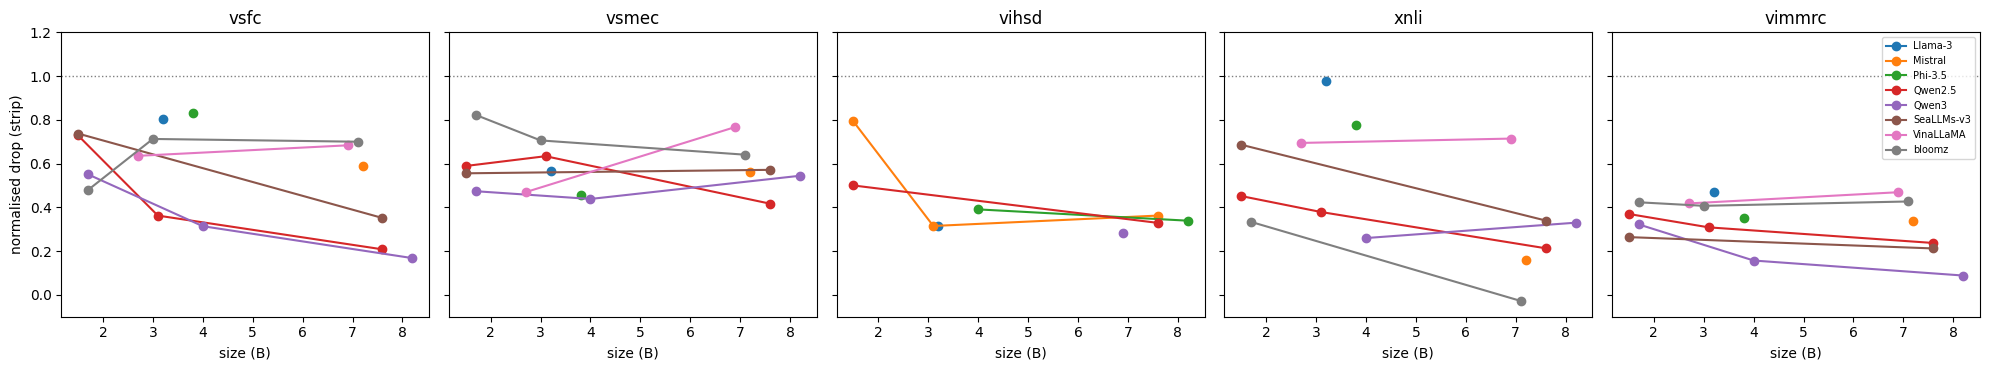

In [16]:
import matplotlib.pyplot as plt

s = summary[summary.gated_in & (summary.cond == "strip")]
fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3.8), sharey=True)
for ax, t in zip(np.atleast_1d(axes), TASKS):
    for fam, g in s[s.task == t].groupby("family"):
        g = g.sort_values("size")
        ax.plot(g["size"], g.norm_drop, marker="o", label=fam)
    ax.set(title=t, xlabel="size (B)", ylim=(-0.1, 1.2))
    ax.axhline(1, color="gray", ls=":", lw=1)
np.atleast_1d(axes)[0].set_ylabel("normalised drop (strip)")
np.atleast_1d(axes)[-1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/scale_by_family.png", dpi=150)
plt.show()

In [17]:
noisy = summary[summary.gated_in & (summary.cond != "clean")].dropna(subset=["norm_drop"])
preds_k = ["d_fertility", "d_broken_rate", "d_fragment_rate", "ppl_ratio"]
corr = pd.DataFrame([
    {"task": t, **{k: spearmanr(g[k], g["norm_drop"])[0] for k in preds_k}, "points": len(g)}
    for t, g in list(noisy.groupby("task")) + [("ALL", noisy)]
]).set_index("task")
print("Spearman ρ with the normalised drop, across gated (model × noisy condition) points")
corr.round(2)

Spearman ρ with the normalised drop, across gated (model × noisy condition) points


,d_fertility,d_broken_rate,d_fragment_rate,ppl_ratio,points
task,,,,,
vihsd,0.62,0.72,-0.53,0.32,54
vimmrc,0.44,0.37,-0.60,0.68,96
vsfc,0.41,0.41,-0.33,0.54,96
vsmec,0.62,0.64,-0.58,0.55,96
xnli,0.29,0.29,-0.52,0.64,84
ALL,0.39,0.41,-0.36,0.55,426


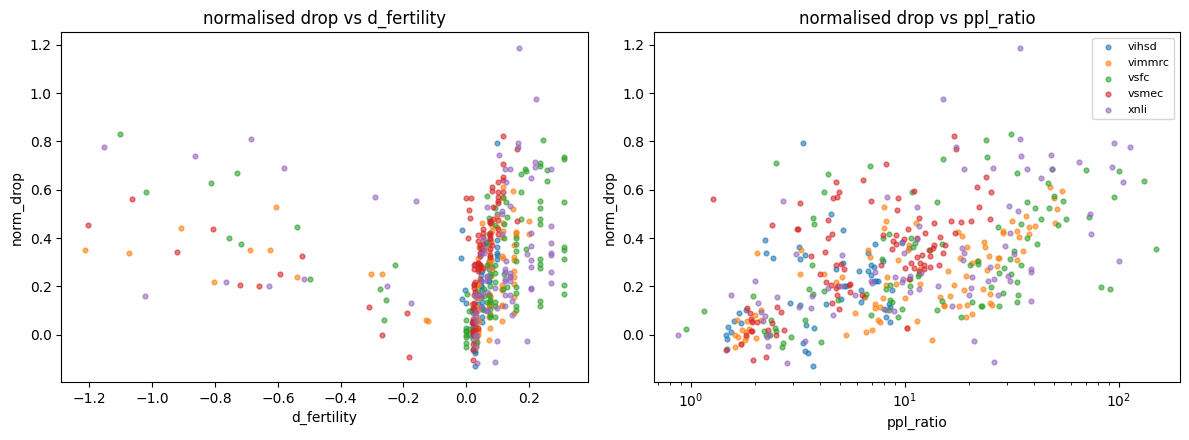

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, k in zip(axes, ["d_fertility", "ppl_ratio"]):
    for t, g in noisy.groupby("task"):
        ax.scatter(g[k], g["norm_drop"], s=12, alpha=0.6, label=t)
    ax.set(title=f"normalised drop vs {k}", xlabel=k, ylabel="norm_drop")
axes[1].set_xscale("log")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/drop_vs_predictors.png", dpi=150)
plt.show()

## 7. Item-level analysis: tokenizer or exposure?

Every (model, task, item, noisy condition) that was **right on the clean version**: did it **flip** to wrong?

Predictors (z-scores): `d_tok` (extra tokens per syllable) and `broken` (share of broken syllables) for the **tokenizer**; `d_nll` (extra NLL per syllable) for **exposure**; and **`log_len`** (log of the clean length in syllables) as a control, new in v2.1. Fixed effects for model, task and condition; standard errors clustered by (task, item).

The last table repeats the "both" model on (model, task) pairs with clean label mass ≥ 50% only, to check that models that would rather answer in another form do not drive the result.

In [19]:
import statsmodels.formula.api as smf

it = preds.merge(tok_items, on=["model", "task", "item_id", "cond"], suffixes=("", "_tok"))
gated = set(map(tuple, summary[summary.gated_in & (summary.cond == "clean")][["model", "task"]].values))
it = it[[(m, t) in gated for m, t in zip(it.model, it.task)]]
it["nll_syl"] = it.nll / it.clean_syl
base = it[it.cond == "clean"][["model", "task", "item_id", "correct", "n_tok", "nll_syl", "label_mass"]]
x = it[it.cond != "clean"].merge(base, on=["model", "task", "item_id"], suffixes=("", "_clean"))
x = x[(x.correct_clean == 1) & (x.n_syl > 0)].copy()
x["flip"] = 1 - x.correct
x["d_tok"] = (x.n_tok - x.n_tok_clean) / x.clean_syl
x["broken"] = x.n_broken / x.n_syl
x["d_nll"] = x.nll_syl - x.nll_syl_clean
x["log_len"] = np.log(x.clean_syl)
for k in ["d_tok", "broken", "d_nll", "log_len"]:
    x[f"z_{k}"] = (x[k] - x[k].mean()) / x[k].std()
x["cluster"] = pd.factorize(x.task + "-" + x.item_id.astype(str))[0]
x.to_csv(f"{OUT_DIR}/item_level.csv", index=False)

print(f"{len(x)} rows, flip rate {x.flip.mean():.2f}, {x.model.nunique()} models, {x.task.nunique()} tasks")
print("correlation between predictors:\n", x[["d_tok", "broken", "d_nll", "log_len"]].corr().round(2))

FIXED = "C(model) + C(task) + C(cond)"
FORMULAS = {
    "length only": f"flip ~ z_log_len + {FIXED}",
    "tokenizer": f"flip ~ z_d_tok + z_broken + z_log_len + {FIXED}",
    "exposure": f"flip ~ z_d_nll + z_log_len + {FIXED}",
    "both": f"flip ~ z_d_tok + z_broken + z_d_nll + z_log_len + {FIXED}",
}
def fit(formula, df):
    try:
        return smf.logit(formula, data=df).fit(disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": df.cluster})
    except Exception as e:  # e.g. perfect separation on a small subset
        print("   fit failed:", formula.split("+")[0], "…", repr(e)[:120])
        return None

fits = {k: fit(f, x) for k, f in FORMULAS.items()}
print("\nmodel comparison (lower AIC = better):\n",
      pd.DataFrame({k: {"AIC": v.aic, "pseudo_R2": v.prsquared} for k, v in fits.items() if v is not None}).T.round(3))
TERMS = ["z_d_tok", "z_broken", "z_d_nll", "z_log_len"]
b = fits["both"]
pd.DataFrame({"coef": b.params, "lo": b.conf_int()[0], "hi": b.conf_int()[1], "p": b.pvalues}).loc[TERMS].round(3)

64776 rows, flip rate 0.26, 16 models, 5 tasks
correlation between predictors:
          d_tok  broken  d_nll  log_len
d_tok     1.00   -0.23   0.19     0.01
broken   -0.23    1.00  -0.03     0.05
d_nll     0.19   -0.03   1.00    -0.01
log_len   0.01    0.05  -0.01     1.00

model comparison (lower AIC = better):
                    AIC  pseudo_R2
length only  67765.549      0.086
tokenizer    67650.323      0.087
exposure     67665.312      0.087
both         67528.584      0.089


,coef,lo,hi,p
z_d_tok,-0.040,-0.120,0.041,0.337
z_broken,-0.146,-0.239,-0.053,0.002
z_d_nll,0.138,0.082,0.194,0.000
z_log_len,-0.107,-0.242,0.028,0.122


In [20]:
rows = []
for t, g in x.groupby("task"):
    f = fit(f"flip ~ z_d_tok + z_broken + z_d_nll + z_log_len + C(model) + C(cond)", g)
    if f is None:
        continue
    rows.append({"task": t, "rows": len(g), **{f"{k}": f.params[k] for k in TERMS}, **{f"p_{k}": f.pvalues[k] for k in TERMS}})
hm = x[x.label_mass_clean >= 0.5]
f = fit(FORMULAS["both"], hm)
if f is not None:
    rows.append({"task": "ALL, label mass ≥ 50%", "rows": len(hm), **{k: f.params[k] for k in TERMS}, **{f"p_{k}": f.pvalues[k] for k in TERMS}})
print("'both' model per task, and on high-label-mass pairs only (coefficients, then p-values)")
pd.DataFrame(rows).set_index("task").round(3)

'both' model per task, and on high-label-mass pairs only (coefficients, then p-values)


,rows,z_d_tok,z_broken,z_d_nll,z_log_len,p_z_d_tok,p_z_broken,p_z_d_nll,p_z_log_len
task,,,,,,,,,
vihsd,8472,-0.116,-0.176,0.181,0.081,0.190,0.044,0.008,0.555
vimmrc,12090,0.003,0.415,-0.422,-0.019,0.985,0.153,0.029,0.941
vsfc,20256,0.065,-0.254,0.181,-0.277,0.202,0.000,0.000,0.015
vsmec,9468,-0.156,-0.098,0.016,0.037,0.214,0.411,0.851,0.834
xnli,14490,-0.041,-0.035,0.224,-0.157,0.607,0.786,0.001,0.356
"ALL, label mass ≥ 50%",47724,-0.041,-0.144,0.173,-0.108,0.315,0.003,0.000,0.154


## 8. Real noise: ViHSD

ViHSD comments come from social media, and many already lack diacritics before we touch them. If models are hurt by missing diacritics, they should already be **worse on the comments that were originally less accented**, in the *clean* condition. This is the natural-noise check reviewers ask for.

In [21]:
if "vihsd" in TASKS:
    v = preds[(preds.task == "vihsd") & (preds.cond == "clean")].merge(
        DATA["vihsd"][DATA["vihsd"].cond == "clean"][["item_id", "clean"]], on="item_id")
    v["original_accent"] = v.clean.map(accent_share)
    v["accent_group"] = pd.cut(v.original_accent, [-0.01, 0.4, 0.7, 1.0], labels=["mostly unaccented", "partly", "fully accented"])
    gm = v[[(m, "vihsd") in gated for m in v.model]]
    print("items per group:", gm.drop_duplicates("item_id").accent_group.value_counts().to_dict())
    display(gm.pivot_table(index="model", columns="accent_group", values="correct", aggfunc="mean", observed=False).loc[
        [m for m in MODELS if m in gm.model.unique()]].round(2))

items per group: {'fully accented': 178, 'partly': 78, 'mostly unaccented': 44}


accent_group,mostly unaccented,partly,fully accented
model,,,
Qwen/Qwen2.5-1.5B-Instruct,0.50,0.55,0.49
SeaLLMs/SeaLLMs-v3-1.5B-Chat,0.43,0.60,0.51
Qwen/Qwen2.5-3B-Instruct,0.43,0.62,0.49
Qwen/Qwen3-4B,0.45,0.62,0.54
Qwen/Qwen2.5-7B-Instruct,0.52,0.67,0.53
Qwen/Qwen3-8B,0.48,0.63,0.50
SeaLLMs/SeaLLMs-v3-7B-Chat,0.45,0.69,0.57
vilm/vinallama-7b-chat,0.39,0.54,0.45
meta-llama/Llama-3.2-3B-Instruct,0.45,0.62,0.52


## 9. What to write in your paper note

1. **Diagnostics first.** Check `label_mass` and `diagnostics.csv` for every (model, task) below the gate or with mass < 50%.
2. **Scale within a family** (the plot in section 6): do larger models lose less, with the tokenizer fixed?
3. **Tokenizer vs exposure** at item level (section 7): which coefficient survives once length is controlled, in all tasks and on high-mass pairs?
4. **Task differences:** which tasks are most fragile (reasoning, reading comprehension, short social media text)?
5. **Real noise** (section 8): are models already worse on comments that were unaccented to begin with?

Then: `Runtime → Disconnect and delete runtime`.